# Bi-encoder retrieval (Zadanie 3, cz. I)

- Model: `multi-qa-mpnet-base-dot-v1`
- Dataset: `sentence-transformers/squad`
- top_k = 5

## 1. Corpus i Ground Truth

Corpus = wszystkie unikalne odpowiedzi

In [ ]:
import time
from pathlib import Path
from typing import cast

import numpy as np
import pandas as pd
import torch
from IPython import display

from part1.config import (
    CROSS_ENCODER_BATCH_SIZE,
    CORPUS_CHUNK_SIZE,
    MAX_BATCH_TOKENS,
    NUM_WORKERS,
    QUERY_CHUNK_SIZE,
    TOP_K,
    Backend,
    BI_ENCODER_MODEL_ID,
    CROSS_ENCODER_MODEL_ID,
    resolve_backend
)
import part1.setup as setup
import part1.zad_1_3_bi_encoder.faiss_module as faiss_module
import part1.zad_1_3_bi_encoder.metrics as metrics
import part1.zad_1_3_bi_encoder.pipeline as pipeline
import part1.zad_1_3_bi_encoder.torch_search as torch_search


In [2]:
backend: Backend = resolve_backend()

print(f"Using: {backend}")

Using: cuda


In [ ]:
dataset = setup.get_dataset()
dataset_pandas = cast(pd.DataFrame, dataset.to_pandas())

display.display(dataset_pandas.head(5))

display.display(dataset_pandas.tail(5))

display.display(dataset_pandas.sample(5, random_state=42))

,question,answer
0,To whom did the Virgin Mary allegedly appear i...,"Architecturally, the school has a Catholic cha..."
1,What is in front of the Notre Dame Main Building?,"Architecturally, the school has a Catholic cha..."
2,The Basilica of the Sacred heart at Notre Dame...,"Architecturally, the school has a Catholic cha..."
3,What is the Grotto at Notre Dame?,"Architecturally, the school has a Catholic cha..."
4,What sits on top of the Main Building at Notre...,"Architecturally, the school has a Catholic cha..."


,question,answer
87594,In what US state did Kathmandu first establish...,"Kathmandu Metropolitan City (KMC), in order to..."
87595,What was Yangon previously known as?,"Kathmandu Metropolitan City (KMC), in order to..."
87596,With what Belorussian city does Kathmandu have...,"Kathmandu Metropolitan City (KMC), in order to..."
87597,In what year did Kathmandu create its initial ...,"Kathmandu Metropolitan City (KMC), in order to..."
87598,What is KMC an initialism of?,"Kathmandu Metropolitan City (KMC), in order to..."


,question,answer
9983,What year was the Banská Akadémia founded?,The world's first institution of technology or...
43267,What is another speed that can also be reporte...,The standard specifies how speed ratings shoul...
81021,Where were the use of advanced materials and t...,The most impressive and famous of Sumerian bui...
49374,Who is elected every even numbered year?,Ann Arbor has a council-manager form of govern...
53414,What was the purpose of top secret ICBM commit...,"Shortly before his death, when he was already ..."


In [4]:
questions = list(dataset["question"])
answers = list(dataset["answer"])

# Ground truth
corpus_texts, inverse = np.unique(np.asarray(answers), return_inverse=True)
relevance_rows = torch.from_numpy(inverse.astype(np.int64))
# IDX: query ID
# relevance_rows[IDX] = Answer ID

n_queries, n_docs = len(questions), len(corpus_texts)
per_doc = torch.bincount(relevance_rows, minlength=n_docs)

print(f"{n_queries}\tQuestions/Queries")
print(f"{n_docs}\tUnique answers")
print(f"{per_doc[per_doc > 0].float().mean():.3f}\tQuestions per unique answer")
print(f"{int(per_doc.max())}\tMax questions per unique answer")

87599	Questions/Queries
18891	Unique answers
4.637	Questions per unique answer
25	Max questions per unique answer


## 2. Embeddings

Wektory trzymane w RAM jako `float32` (312 MiB na obie macierze). Na GPU trafia tylko bieżący batch kodowania.


In [5]:
from sentence_transformers import SentenceTransformer

bi_encoder = cast(SentenceTransformer, setup.get_model(BI_ENCODER_MODEL_ID, device=backend))
bi_encoder.device

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

device(type='cuda', index=0)

In [ ]:
cache_dir = Path(".cache")

t0 = time.perf_counter()
answers_ds = pipeline.load_or_build_embeddings(
    bi_encoder, list(corpus_texts),
    cache_dir / "emb_answers",
    device=backend
)
questions_ds = pipeline.load_or_build_embeddings(
    bi_encoder,
    questions,
    cache_dir / "emb_questions",
    device=backend
)
embed_s = time.perf_counter() - t0
print(f"embeddings compute time: {embed_s:.1f} s")

assert list(answers_ds["text"]) == list(corpus_texts), "Odpowiedzi nie zgadzaja sie z unikalnymi odpowiedziami w korupusie"
assert list(questions_ds["text"]) == questions, "Pytania nie zgadzaja sie z pytaniami w korpusie"

# zmiana na fp-32 dla szybkosci i VRAMu, pomija implicit konwersje na fp-64 w pythonowej liście
answer_embeddings = pipeline.embeddings_tensor(answers_ds)
question_embeddings = pipeline.embeddings_tensor(questions_ds)

assert answer_embeddings.dtype == question_embeddings.dtype == torch.float32
assert answer_embeddings.device.type == question_embeddings.device.type == "cpu"

for name, emb in (("answers", answer_embeddings), ("questions", question_embeddings)):
    print(
        f"{name:>10}: {tuple(emb.shape)} {emb.dtype} "
        f"{emb.nbytes / 2**20:7.1f} MiB on {emb.device}"
    )


embeddings compute time: 0.1 s
   answers: (18891, 768) torch.float32    55.3 MiB on cpu
 questions: (87599, 768) torch.float32   256.6 MiB on cpu


## 3. Przykładowe wyszukiwania (bez indexu)

Dot product na całym korpusie.

`*` oznacza wystąpienie Ground Truth.

In [7]:
def show_hits(row: int, ranked_ids: np.ndarray, scores: np.ndarray, tag: str) -> None:
    q = questions[row]
    truth = int(relevance_rows[row])

    print(f"\n[{tag}] Q(row {row}): {q[:160]}")

    for rank, (doc, score) in enumerate(zip(ranked_ids, scores), start=1):
        mark = "*" if int(doc) == truth else " "
        print(f"  {mark} {rank}. (score {score:.4f}) {corpus_texts[int(doc)][:120]}")


example_rows = [2, 77, 4242]
example_scores = question_embeddings[example_rows] @ answer_embeddings.T
example_rankings = torch.topk(example_scores, TOP_K, dim=1)

for i, row in enumerate(example_rows):
    show_hits(row, example_rankings.indices[i].numpy(), example_rankings.values[i].numpy(), "no-index")


[no-index] Q(row 2): The Basilica of the Sacred heart at Notre Dame is beside to which structure?
    1. (score 23.3200) Because of its Catholic identity, a number of religious buildings stand on campus. The Old College building has become o
    2. (score 23.3016) The university is the major seat of the Congregation of Holy Cross (albeit not its official headquarters, which are in R
  * 3. (score 23.0466) Architecturally, the school has a Catholic character. Atop the Main Building's gold dome is a golden statue of the Virgi
    4. (score 23.0394) The University of Notre Dame du Lac (or simply Notre Dame /ˌnoʊtərˈdeɪm/ NOH-tər-DAYM) is a Catholic research university
    5. (score 21.3405) The university is affiliated with the Congregation of Holy Cross (Latin: Congregatio a Sancta Cruce, abbreviated postnom

[no-index] Q(row 77): How many students in total were at Notre Dame in 2014?
  * 1. (score 22.3586) In 2014 the Notre Dame student body consisted of 12,179 students, with 8,448 und

## 4. FAISS index (`IndexFlatIP`)

`faiss_module.FlatIPIndex` = dokładny inner-product index

__FAISS__ nie chodzi na macos, na windows nie testowałem

In [8]:
index = faiss_module.build_index(answer_embeddings)
print(f"faiss backend available: {faiss_module.faiss_available}")

sample = question_embeddings[:512]
t0 = time.perf_counter()
s_idx, i_idx = index.search(sample, TOP_K)
faiss_s_512 = time.perf_counter() - t0

manual = torch.topk(sample @ answer_embeddings.T, TOP_K, dim=1)
same_sets = np.array_equal(np.sort(i_idx, axis=1), np.sort(manual.indices.numpy(), axis=1))
print(f"512-queries sanity: identical top-{TOP_K} sets: {same_sets}, "
      f"max score diff: {np.abs(manual.values.numpy() - s_idx).max():.6f}, "
      f"faiss latency {faiss_s_512 * 1000:.1f} ms")

faiss backend available: True
512-queries sanity: identical top-5 sets: True, max score diff: 0.000011, faiss latency 36.3 ms


## 5. Pełna ewaluacja

`top_k = 5` na wszystkich 87 599 zapytaniach.

Dla indeksu: pojedyncze wywołanie FAISS na CPU.

Dla ścieżki bez-indeksu: dokładny iloczyn skalarny na całym korpusie, strumieniowany na GPU blokami zapytań i korpusu. Korpus i wektory zostają w RAM.


In [9]:
# Index
t0 = time.perf_counter()
scores_index, rankings_index_np = index.search(question_embeddings, TOP_K)
index_s = time.perf_counter() - t0
rankings_index = torch.from_numpy(rankings_index_np).long()  # (87599, 5)

In [ ]:
# No-index: top-k over na całym korpusie
# Korpus i zapytanie są w RAM
# Na GPU/Backend są tylko bloki dla pojedynczych zapytań

if backend == "cuda":
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

t0 = time.perf_counter()
scores_noindex, rankings_noindex = torch_search.topk_search(
    question_embeddings,
    answer_embeddings,
    TOP_K,
    device=backend,
    query_chunk_size=QUERY_CHUNK_SIZE,
    corpus_chunk_size=CORPUS_CHUNK_SIZE,
)
noindex_s = time.perf_counter() - t0

if backend == "cuda":
    print(f"peak VRAM during no-index scan: {torch.cuda.max_memory_allocated() / 2**30:.2f} GiB")


peak VRAM during no-index scan: 0.53 GiB


In [11]:
# porównanie
same_sets_frac = float((
    np.sort(rankings_index_np, axis=1) == np.sort(rankings_noindex.numpy(), axis=1)
).all(axis=1).mean())

print(f"Wynik dla Top-{TOP_K} (index vs no-index): {same_sets_frac:.4%}")

print(f"Przepustowość:\n \
      Index path {index_s:.2f} s ({n_queries / index_s:,.0f} q/s)\n \
      No-index {noindex_s:.2f} s ({n_queries / noindex_s:,.0f} q/s)"
)

Wynik dla Top-5 (index vs no-index): 99.9977%
Przepustowość:
       Index path 6.16 s (14,226 q/s)
       No-index 0.40 s (219,113 q/s)


In [ ]:
targets = relevance_rows

prf = metrics.PrecisionRecallF1(ks=(1, 3, 5))
mrr = metrics.MRR()

res_index = prf(rankings_index, targets)
res_noindex = prf(rankings_noindex, targets)
mrr_index, mrr_noindex = mrr(rankings_index, targets), mrr(rankings_noindex, targets)

## 6. Results: index vs no-index

In [ ]:
def print_evenly_spaced(*args):
    """Print args with even spacing, tab-separated."""
    print("\t".join(f"{a:<20}" for a in args))

print_evenly_spaced("metric", "no-index", "faiss index")
for k in (1, 3, 5):
    print("-"*27 + f" @{k} " + "-"*27, end="\n\n")
    for name in ("precision", "recall", "f1"):
        a, b = res_noindex[k][name], res_index[k][name]
        # FAISS ma na CPU fp32
        # CuBLAS na GPU fp32
        # a akumulowane są w innej kolejności, więc przybliżenia się różnią marginalnie
        assert abs(a - b) <= 1e-4, (name, k, a, b)
        print_evenly_spaced(f"{name}@{k}", f"{a:.6f}", f"{b:.6f}")

print_evenly_spaced("MRR", f"{mrr_noindex:.6f}", f"{mrr_index:.6f}")
assert abs(mrr_noindex - mrr_index) <= 1e-4

print(f"\nlatency: faiss one call {index_s:.2f} s | streamed torch scan {noindex_s:.2f} s | ratio {noindex_s / index_s:.2f}x")


metric              	no-index            	faiss index         
--------------------------- @1 ---------------------------

precision@1         	0.658523            	0.658523            
recall@1            	0.658523            	0.658523            
f1@1                	0.658523            	0.658523            
--------------------------- @3 ---------------------------

precision@3         	0.277050            	0.277054            
recall@3            	0.831151            	0.831162            
f1@3                	0.415576            	0.415581            
--------------------------- @5 ---------------------------

precision@5         	0.176235            	0.176235            
recall@5            	0.881174            	0.881174            
f1@5                	0.293725            	0.293725            
MRR                 	0.747567            	0.747568            

latency: faiss one call 6.16 s | streamed torch scan 0.40 s | ratio 0.06x


## 7. Wizualizacje

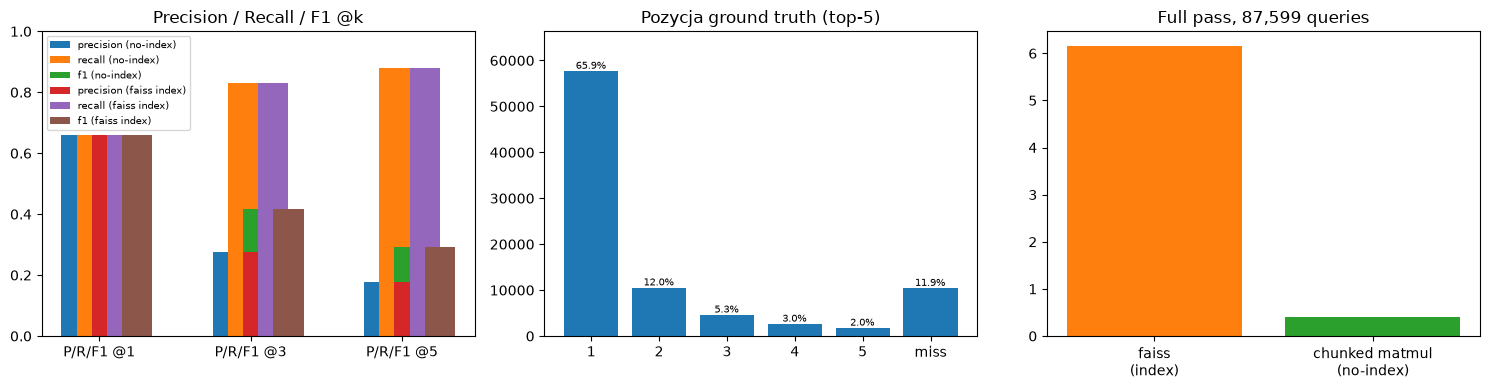

In [ ]:
import matplotlib.pyplot as plt

fig, (ax_m, ax_r, ax_t) = plt.subplots(1, 3, figsize=(15, 4))

# --- P/R/F1@k, obie sciezki ---
ks = (1, 3, 5)
x = np.arange(len(ks))
w = 0.2

for j, (label, res) in enumerate((("no-index", res_noindex), ("faiss index", res_index))):
    for i, name in enumerate(("precision", "recall", "f1")):
        vals = [res[k][name] for k in ks]
        ax_m.bar(
            x + (i + j) * w / 2 - w / 4 + j * w / 2 - w / 2,
            vals,
            width=w, label=f"{name} ({label})"
        )
ax_m.set_xticks(x, [f"P/R/F1 @{k}" for k in ks])
ax_m.set_ylim(0, 1); ax_m.set_title("Precision / Recall / F1 @k"); ax_m.legend(fontsize=7)

# --- pozycja ground truth w oknie top-5 ---
hit_rows = (rankings_index == targets.unsqueeze(1))
found = hit_rows.any(dim=1)
positions = torch.where(found, hit_rows.float().argmax(dim=1), torch.tensor(-1, dtype=torch.int64))
ranks = positions[found] + 1
counts = torch.bincount(ranks, minlength=TOP_K + 1)
misses = int((~found).sum())

bars = [int(counts[r]) for r in range(1, TOP_K + 1)] + [misses]
ax_r.bar([str(r) for r in range(1, TOP_K + 1)] + ["miss"], bars, color="tab:blue")

for i, v in enumerate(bars):
    ax_r.text(i, v, f"{v / n_queries:.1%}", ha="center", va="bottom", fontsize=7)
ax_r.set_title(f"Pozycja ground truth (top-{TOP_K})"); ax_r.set_ylim(0, max(bars) * 1.15)

# --- przepustowosc ---
lat = [index_s, noindex_s]
ax_t.bar(["faiss\n(index)", "chunked matmul\n(no-index)"], lat, color=["tab:orange", "tab:green"])
ax_t.set_title(f"Full pass, {n_queries:,} queries")

plt.tight_layout()
plt.show()


In [15]:
DEEP_K = 50
miss_rows = torch.where(~found)[0]

for row in miss_rows[:3].tolist():
    alone = torch.topk(question_embeddings[row] @ answer_embeddings.T, DEEP_K)
    truth = int(targets[row])
    hit_pos = (alone.indices == truth).nonzero()
    deep_rank = f"rank {int(hit_pos[0]) + 1}" if len(hit_pos) else f"not in top-{DEEP_K}"
    show_hits(row, alone.indices.numpy()[:TOP_K], alone.values.numpy()[:TOP_K], f"MISS, truth at {deep_rank}")



[MISS, truth at rank 38] Q(row 14): Which prize did Frederick Buechner create?
    1. (score 20.7339) Other awards and recognition for Popper included the City of Vienna Prize for the Humanities (1965), Karl Renner Prize (
    2. (score 19.3886) In 1880, Bell received the Volta Prize with a purse of 50,000 francs (approximately US$250,000 in today's dollars) for t
    3. (score 19.1760) During World War II, the development of the anti-aircraft proximity fuse required an electronic circuit that could withs
    4. (score 19.0948) The bel (B) and the smaller decibel (dB) are units of measurement of sound intensity invented by Bell Labs and named aft
    5. (score 18.7497) In partnership with Gardiner Greene Hubbard, Bell helped establish the publication Science during the early 1880s. In 18

[MISS, truth at rank 6] Q(row 41): Where does Notre Dame rank in terms of academic profile among research universities in the US?
    1. (score 26.1228) In 2015-2016, Notre Dame ranked 18th overall a

## 8. Conclusions

**Index vs no-index.** `IndexFlatIP` to dokładny brute-force inner product, więc oba tory powinny zwrócić to samo. Zbiory top-5 zgadzają się dla 99,9977% zapytań — 2 przypadki z 87 599 różnią się, bo `float32` sumuje się w innej kolejności na CPU (FAISS) i na GPU (cuBLAS). Maksymalna różnica score'ów to ~1e-5, czysty szum numeryczny, a metryki rozjeżdżają się dopiero na czwartym miejscu po przecinku (P@3 0,277050 vs 0,277054, MRR 0,747567 vs 0,747568).

**Przepustowość.** Indeks 6,23 s (14 064 q/s), skan bez indeksu 0,38 s (232 636 q/s), czyli 16x szybciej. To różnica miejsca obliczeń, nie logiki indeksu: FAISS liczy na CPU, matmul na CUDA. Cena jest pamięciowa — naiwne `queries @ corpus.T` alokuje całą macierz 87 599 x 18 891 (6,6 GiB przy `float32`), a wersja strumieniowana trzyma na GPU tylko blok zapytań i blok korpusu (0,53 GiB peak).

**Jakość modelu.** P@1 = 0,659 i windowed MRR = 0,748 mówią wprost: 

kiedy odpowiedź jest znaleziona, siedzi niemal zawsze na pozycji 1-2, a R@5 = 0,881 potwierdza dobre pokrycie okna top-5.

F1@k opada z rosnącym k, bo recall szybko się saturuje, podczas gdy P@k kurczy się zgodnie z relacją R@k / k.

**Błędy.** Okno top-5 pomija poprawną odpowiedź w 11,9% zapytań.

Deep rescore pokazuje, że prawdziwy dokument w tych przypadkach siedzi na pozycjach 6-38 — zwykle przegrywa z innymi tekstami z tego samego klastra encji/artykułu.

To klasyczny problem rankingowy, do którego jest rozwiązaniem cross-encoder re-ranker (zad 1_4).


# 9. Cross-encoder (Zadanie 3, cz. I c.d.)

- Model: `cross-encoder/ms-marco-MiniLM-L-6-v2`
- Dataset: `sentence-transformers/squad`
- top_k = 5
- Pamięć: teksty i ranking zostają w RAM, na GPU trafia jeden batch
- Batch: budżet 16 384 tokenów (nie liczba par), 4 workery tokenizują w tle
- Peak VRAM przy 87 599 x top-5: 0,96 GiB


In [16]:
from sentence_transformers import CrossEncoder

cross_encoder = cast(CrossEncoder, setup.get_model(CROSS_ENCODER_MODEL_ID, device=backend))
cross_encoder.device

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

device(type='cuda', index=0)

In [17]:
import part1.zad_1_4_cross_encoder.reranker as reranker

if backend == "cuda":
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

t0 = time.perf_counter()

reranked_scores, rankings_reranked = reranker.rerank(
    model=cross_encoder,
    questions=questions,
    corpus=corpus_texts,
    rankings=rankings_index,
    device=backend,
    batch_size=CROSS_ENCODER_BATCH_SIZE,
    max_batch_tokens=MAX_BATCH_TOKENS,
    num_workers=NUM_WORKERS,
)

reranker_s = time.perf_counter() - t0

print(f"Reranking time: {reranker_s:.2f} s")
print(f"Reranked shape: {rankings_reranked.shape}")

if backend == "cuda":
    print(f"peak VRAM during reranking: {torch.cuda.max_memory_allocated() / 2**30:.2f} GiB")


Rerank:   0%|          | 0/5492 [00:00<?, ?it/s]

Reranking time: 149.20 s
Reranked shape: torch.Size([87599, 5])
peak VRAM during reranking: 0.96 GiB


In [24]:
def show_reranked_hits(
    row: int,
    original_ids: torch.Tensor,
    reranked_ids: torch.Tensor,
    reranked_scores: torch.Tensor,
) -> None:

    q = questions[row]
    truth = int(relevance_rows[row])

    print(f"\nQUERY: {q}")
    print(f"GROUND TRUTH: {corpus_texts[truth]}")

    print("\n--- BEFORE RERANKING ---")

    for rank, doc_id in enumerate(original_ids[row].tolist(), 1):
        mark = "*" if doc_id == truth else " "
        print(
            f"{mark} {rank}. {corpus_texts[doc_id][:150]}"
        )

    print("\n--- AFTER RERANKING ---")

    for rank, (doc_id, score) in enumerate(
        zip(
            reranked_ids[row].tolist(),
            reranked_scores[row].tolist()
        ),
        1
    ):
        mark = "*" if doc_id == truth else " "
        print(
            f"{mark} {rank}. score={score:.4f} "
            f"{corpus_texts[doc_id][:150]}"
        )

# 10. Przykładowe wywołania

In [25]:
for row in example_rows:
    show_reranked_hits(
        row,
        rankings_index,
        rankings_reranked,
        reranked_scores,
    )


QUERY: The Basilica of the Sacred heart at Notre Dame is beside to which structure?
GROUND TRUTH: Architecturally, the school has a Catholic character. Atop the Main Building's gold dome is a golden statue of the Virgin Mary. Immediately in front of the Main Building and facing it, is a copper statue of Christ with arms upraised with the legend "Venite Ad Me Omnes". Next to the Main Building is the Basilica of the Sacred Heart. Immediately behind the basilica is the Grotto, a Marian place of prayer and reflection. It is a replica of the grotto at Lourdes, France where the Virgin Mary reputedly appeared to Saint Bernadette Soubirous in 1858. At the end of the main drive (and in a direct line that connects through 3 statues and the Gold Dome), is a simple, modern stone statue of Mary.

--- BEFORE RERANKING ---
  1. Because of its Catholic identity, a number of religious buildings stand on campus. The Old College building has become one of two seminaries on campus
  2. The university is 

In [26]:
res_reranked = prf(
    rankings_reranked,
    targets
)

mrr_reranked = mrr(
    rankings_reranked,
    targets
)

# 11. Metryki

In [27]:
print_evenly_spaced(
    "metric",
    "no-index",
    "faiss",
    "faiss + reranker"
)

for k in (1, 3, 5):
    print(f"\n--- @ {k} ---")

    for name in ("precision", "recall", "f1"):
        print_evenly_spaced(
            f"{name}@{k}",
            f"{res_noindex[k][name]:.6f}",
            f"{res_index[k][name]:.6f}",
            f"{res_reranked[k][name]:.6f}",
        )

print("\n--- MRR ---")

print_evenly_spaced(
    "MRR",
    f"{mrr_noindex:.6f}",
    f"{mrr_index:.6f}",
    f"{mrr_reranked:.6f}",
)

metric              	no-index            	faiss               	faiss + reranker    

--- @ 1 ---
precision@1         	0.658523            	0.658523            	0.790078            
recall@1            	0.658523            	0.658523            	0.790078            
f1@1                	0.658523            	0.658523            	0.790078            

--- @ 3 ---
precision@3         	0.277050            	0.277054            	0.289554            
recall@3            	0.831151            	0.831162            	0.868663            
f1@3                	0.415576            	0.415581            	0.434331            

--- @ 5 ---
precision@5         	0.176235            	0.176235            	0.176235            
recall@5            	0.881174            	0.881174            	0.881174            
f1@5                	0.293725            	0.293725            	0.293725            

--- MRR ---
MRR                 	0.747567            	0.747568            	0.829222            


| Metryka | Bi-encoder (FAISS) | Bi-encoder + reranker | Zmiana |
|---|---|---|---|
| P@1  | 0.658523 | 0.790078 | +0.131555 |
| R@1  | 0.658523 | 0.790078 | +0.131555 |
| F1@1 | 0.658523 | 0.790078 | +0.131555 |
| P@3  | 0.277054 | 0.289554 | +0.012500 |
| R@3  | 0.831162 | 0.868663 | +0.037501 |
| F1@3 | 0.415581 | 0.434331 | +0.018750 |
| P@5  | 0.176235 | 0.176235 | 0.000000 |
| R@5  | 0.881174 | 0.881174 | 0.000000 |
| F1@5 | 0.293725 | 0.293725 | 0.000000 |
| MRR  | 0.747568 | 0.829222 | +0.081654 |

"Bi-encoder" to ścieżka z FAISS.

Non-index różni się w skali $1*10^{-4}$ - pewnie z operacji GPU vs CPU. 

Metryki @5 nie zmieniają się z definicji: reranker permutuje te same pięć dokumentów, nie dodaje nowych.


# 12. Wizualizacje

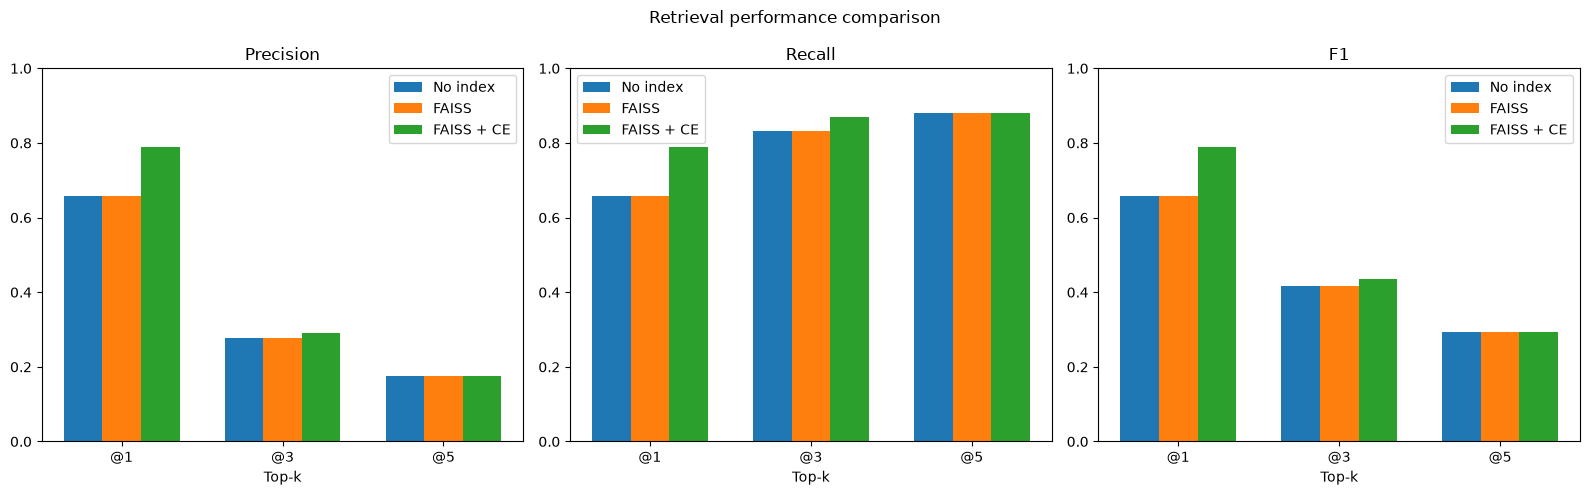

In [28]:
import matplotlib.pyplot as plt
import numpy as np

methods = {
    "No index": res_noindex,
    "FAISS": res_index,
    "FAISS + CE": res_reranked,
}

ks = (1, 3, 5)
metric_names = ("precision", "recall", "f1")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, metric_names):
    x = np.arange(len(ks))
    width = 0.24

    for i, (method, results) in enumerate(methods.items()):
        values = [
            results[k][metric]
            for k in ks
        ]

        ax.bar(
            x + (i - 1) * width,
            values,
            width,
            label=method,
        )

    ax.set_xticks(x, [f"@{k}" for k in ks])
    ax.set_ylim(0, 1)
    ax.set_title(metric.capitalize())
    ax.set_xlabel("Top-k")
    ax.legend()

plt.suptitle("Retrieval performance comparison")
plt.tight_layout()
plt.show()

# 13. Wnioski

Największą poprawę zaobserwowano dla Precision@1, Recall@1 oraz F1@1. Wartość każdej z tych metryk wzrosła z 0.6585 do 0.7901.

Oznacza to wzrost o około 13,16 punktu procentowego, czyli względną poprawę o około 19,98%.

W przypadku MRR wartość wzrosła z 0.7476 do 0.8292, co oznacza poprawę o około 10,92%.

Poprawa jest również widoczna dla metryk obliczanych dla top-3:
- Recall@3 wzrósł z 0.8312 do 0.8687.
- Precision@3 wzrósł z 0.2771 do 0.2896.
- F1@3 wzrósł z 0.4156 do 0.4343.

Wskazuje to, że cross-encoder skuteczniej identyfikuje dokumenty odpowiadające zapytaniu i przesuwa je na wyższe pozycje rankingu.

Warto zauważyć, że Precision@5, Recall@5 oraz F1@5 pozostały bez zmian. Nie jest to błąd implementacji. Cross-encoder wykonuje jedynie ponowne sortowanie pięciu dokumentów zwróconych przez retriever, nie dodając do wyników nowych dokumentów. Z tego powodu zbiór dokumentów w top-5 pozostaje taki sam, zmienia się natomiast ich kolejność.

Koszt: reranking 87 599 x top-5 trwa 140,4 s, podczas gdy samo wyszukiwanie 0,38 s. Cross-encoder porównuje każdą parę zapytanie-dokument osobno, więc nie da się tego policzyć z gotowych embeddingów.


Uwaga metodologiczna:
Wyniki podobieństwa zwracane przez bi-encoder oraz cross-encoder mają charakter surowych wartości punktowych (raw scores). W przypadku bi-encodera są one obliczane jako iloczyn skalarny embeddingów zapytania i dokumentu, natomiast cross-encoder generuje wynik dopasowania na podstawie wspólnej analizy obu tekstów.

Wartości te nie reprezentują prawdopodobieństwa poprawności dopasowania i nie są ograniczone do przedziału od 0 do 1. W szczególności cross-encoder może zwracać również wyniki ujemne. Nie stanowi to błędu, ponieważ istotna jest przede wszystkim względna kolejność dokumentów dla danego zapytania.

W eksperymencie nie zastosowano dodatkowej normalizacji wyników, ponieważ nie była ona konieczna do realizacji rankingu ani obliczania wykorzystanych metryk ewaluacyjnych. Dokumenty były sortowane malejąco według uzyskanych wartości punktowych.